# Лабораторна робота № 7
## Логістична регресія. «Врятувати принцесу»


**Мета:** виконати бінарну класифікацію для датасету *Cure the Princess*, побудувати логістичну регресію, підібрати її параметри та порівняти з SVM і деревом рішень.

**Датасет:** [завантажити файл](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view?usp=drive_link).

**Завдання:** допишіть код у клітинках із позначкою `TODO`, запустіть усі потрібні клітинки, після кожного етапу коротко прокоментуйте результати. Готові числові результати у шаблоні навмисно не наведено.

https://www.kaggle.com/datasets/unmoved/cure-the-princess

### 1. Імпорт бібліотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

### 2. Завантаження даних

Використайте **один** із двох способів. Якщо обираєте завантаження з комп'ютера, виконайте перший блок. Якщо KaggleHub — другий. Файл має назву `data.csv`.

In [2]:
# Варіант 1. Завантаження файлу в Google Colab
# Варіант 1. Завантаження файлу в Google Colab
from google.colab import files
uploaded = files.upload()

import pandas as pd
df = pd.read_csv('data.csv')

# Первинний перегляд даних
print("Перші 5 рядків датасету:")
display(df.head())

print("\nРозмірність датасету (рядки, колонки):", df.shape)

Saving data.csv to data.csv
Перші 5 рядків датасету:


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0



Розмірність датасету (рядки, колонки): (2338, 14)


### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету

Дослідіть структуру та розміри даних, пропущені значення, дублікати й описову статистику. Дайте короткий висновок про якість даних.

In [3]:
# Виведення перших рядків, структури та розміру датасету
print("Перші рядки датасету:")
display(df.head())

print("\nІнформація про типи даних та пропуски:")
df.info()

print("\nРозмірність датасету:", df.shape)

Перші рядки датасету:


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0



Інформація про типи даних та пропуски:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB

Розмірність датасету: (2338, 14)


In [5]:
# Перевірка кількості пропусків та дублікатів
print("Кількість пропущених значень по колонках:")
print(df.isnull().sum())

print("\nЗагальна кількість повних дублікатів:", df.duplicated().sum())

Кількість пропущених значень по колонках:
Phoenix Feather    0
Unicorn Horn       0
Dragon's Blood     0
Mermaid Tears      0
Fairy Dust         0
Goblin Toes        0
Witch's Brew       0
Griffin Claw       0
Troll Hair         0
Kraken Ink         0
Minotaur Horn      0
Basilisk Scale     0
Chimera Fang       0
Cured              0
dtype: int64

Загальна кількість повних дублікатів: 0


In [6]:
# Описова статистика для всіх числових ознак
df.describe()

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
count,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000
mean,15.365697,10.946749,16.115654,13.627973,15.069504,14.157271,12.328914,14.911206,16.871685,14.890590,10.916125,15.371600,12.084003,0.496578
std,8.669969,7.225162,8.372518,7.545244,8.349340,7.831476,7.709753,8.132678,9.579027,8.014197,7.045195,8.559139,8.047540,0.500095
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,8.500000,5.300000,9.600000,7.600000,8.625000,7.900000,6.325000,8.400000,8.900000,8.800000,5.200000,8.800000,5.600000,0.000000
50%,14.700000,9.500000,15.800000,13.100000,14.500000,13.500000,11.200000,14.400000,16.300000,14.400000,9.700000,14.800000,10.500000,0.000000
75%,21.300000,15.575000,22.000000,19.000000,20.700000,19.500000,16.900000,20.500000,24.000000,20.400000,15.375000,21.100000,17.275000,1.000000
max,42.100000,34.100000,40.800000,35.800000,40.400000,37.800000,37.300000,39.400000,44.800000,39.500000,33.700000,42.000000,37.800000,1.000000


**Висновок за первинним оглядом:**  
У ході первинного огляду датасету встановлено, що дані не містять пропущених значень (0 пропусків) та повторюваних записів (0 дублікатів). Датасет складається з 2338 об'єктів та 14 числових колонок. Ознаки представлені у безперервному числовому форматі (float64) і мають різний розмах значень (наприклад, середні значення варіюються від ~10.9 до ~16.8), що підтверджує необхідність подальшого масштабування (стандартизації) даних перед навчанням моделей. Цільова змінна Cured є збалансованою (близько 50% позитивних і 50% негативних класів).

### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [9]:
# Відокремлення ознак та цільової змінної
X = df.drop(columns=['Cured'])
y = df['Cured']

# Поділ на навчальну (80%) та тестову (20%) вибірки
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Перевірка розмірів вибірок
print(f"Розмір X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"Розмір X_test:  {X_test.shape}, y_test:  {y_test.shape}")

Розмір X_train: (1870, 13), y_train: (1870,)
Розмір X_test:  (468, 13), y_test:  (468,)


### 5. Баланс класів на навчальній вибірці

In [8]:
# Підрахунок кількості спостережень кожного класу в y_train
print("Розподіл класів у y_train (абсолютні значення):")
print(y_train.value_counts())

print("\nРозподіл класів у y_train (у відсотках):")
print(y_train.value_counts(normalize=True) * 100)

Розподіл класів у y_train (абсолютні значення):
Cured
0    941
1    929
Name: count, dtype: int64

Розподіл класів у y_train (у відсотках):
Cured
0    50.320856
1    49.679144
Name: proportion, dtype: float64


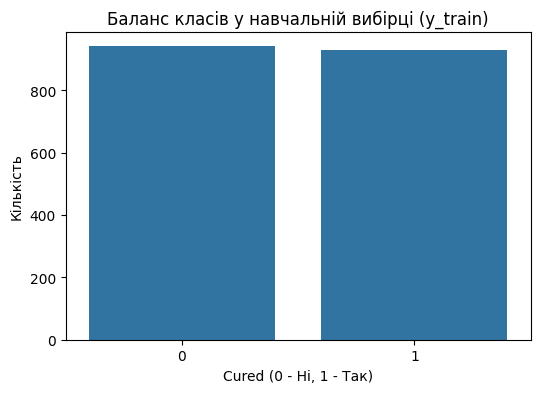

In [10]:
# Візуалізація балансу класів
plt.figure(figsize=(6, 4))
sns.countplot(x=y_train)
plt.title('Баланс класів у навчальній вибірці (y_train)')
plt.xlabel('Cured (0 - Ні, 1 - Так)')
plt.ylabel('Кількість')
plt.show()

**Висновок:**  
_Чи збалансовані класи? Чому це може вплинути на оцінку моделі?_

Класи є повністю збалансованими (клас 0 становить 50.3%, клас 1 — 49.7%).

Якщо класи несбалансовані (наприклад, 90% до 10%), модель може навчитися просто завжди передбачати мажоритарний клас і отримувати високу загальну точність, але при цьому не виявляти цільовий клас взагалі.

### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

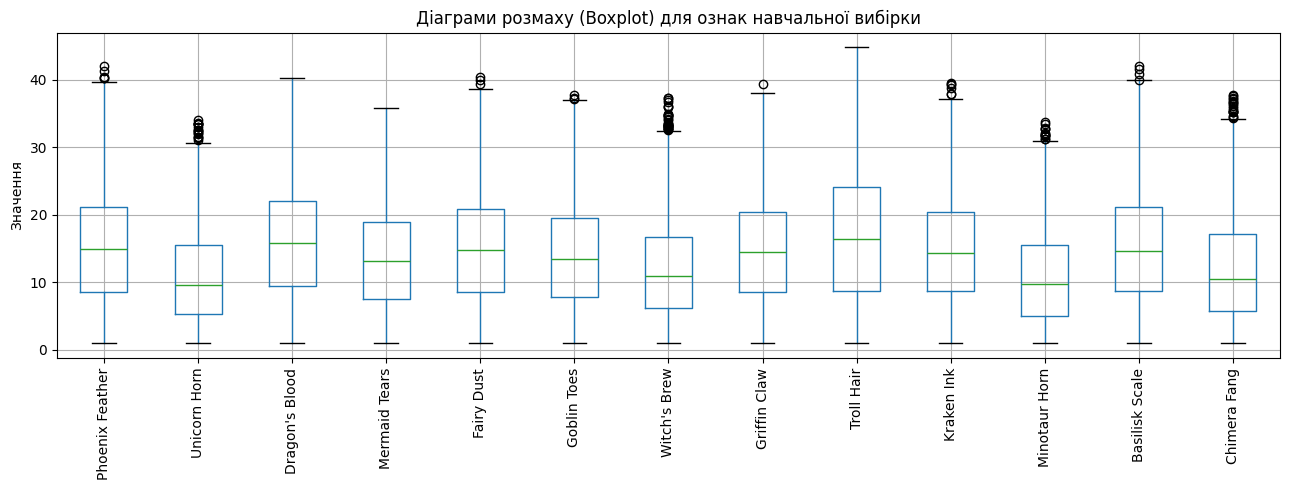

In [11]:
# Побудова діаграм розмаху для ознак X_train
plt.figure(figsize=(13, 5))
X_train.boxplot(rot=90)
plt.title('Діаграми розмаху (Boxplot) для ознак навчальної вибірки')
plt.ylabel('Значення')
plt.tight_layout()
plt.show()

In [12]:
# Обчислення q1, q3 та iqr для X_train
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1

# Пошук кількості викидів за межами [q1 - 1.5*iqr, q3 + 1.5*iqr]
outliers = ((X_train < (q1 - 1.5 * iqr)) | (X_train > (q3 + 1.5 * iqr))).sum()

# Сортування результату за спаданням
outliers_sorted = outliers.sort_values(ascending=False)

print("Кількість потенційних викидів у кожній ознаці (за спаданням):")
print(outliers_sorted)

Кількість потенційних викидів у кожній ознаці (за спаданням):
Witch's Brew       31
Chimera Fang       18
Unicorn Horn       17
Minotaur Horn      13
Kraken Ink          6
Phoenix Feather     5
Basilisk Scale      4
Fairy Dust          3
Goblin Toes         3
Griffin Claw        1
Dragon's Blood      0
Mermaid Tears       0
Troll Hair          0
dtype: int64


**Висновок про викиди:**  
_У яких ознаках їх найбільше? Чому не варто без перевірки видаляти всі такі рядки?_

Найбільша кількість потенційних викидів за правилом $1.5 \times IQR$ зафіксована в ознаках Witch's Brew (31), Chimera Fang (18) та Unicorn Horn (17); в ознаках Dragon's Blood, Mermaid Tears та Troll Hair викиди відсутні. Видаляти всі такі рядки без перевірки не варто, оскільки крайні значення інгредієнтів можуть містити важливу інформацію для класифікації, а їх видалення зменшить навчальну вибірку та призведе до втрати рідкісних паттернів.

### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

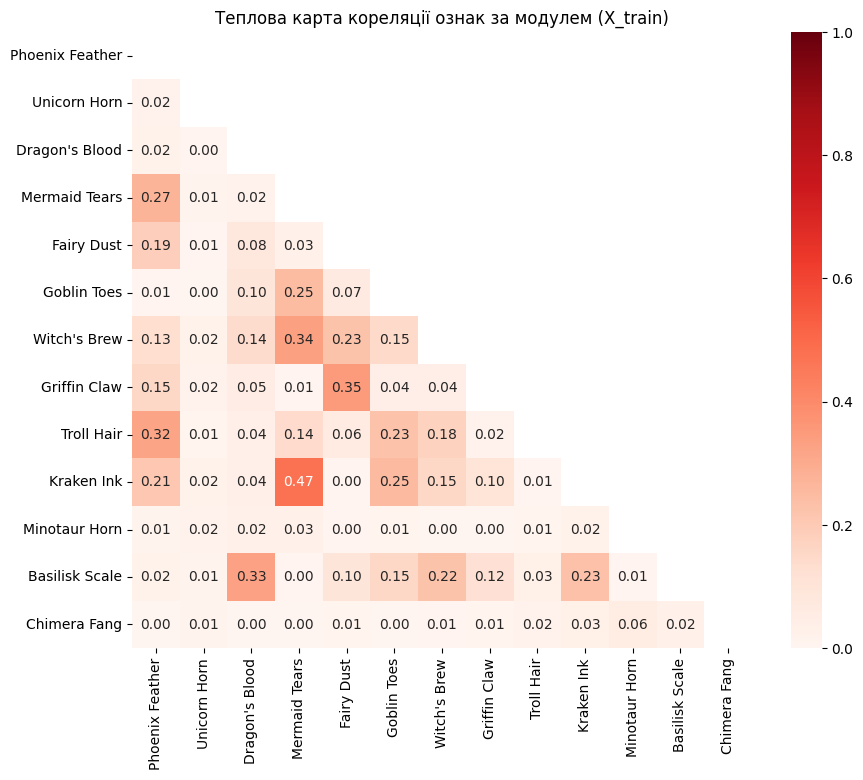

In [13]:
# Обчислення кореляційної матриці за модулем
mtx = X_train.corr().abs()

# Маска для верхнього трикутника
mask = np.triu(np.ones_like(mtx, dtype=bool))

# Побудова heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(mtx, mask=mask, annot=True, fmt='.2f', cmap='Reds', vmin=0, vmax=1)
plt.title('Теплова карта кореляції ознак за модулем (X_train)')
plt.show()

In [14]:
# Обєднання X_train та y_train для кореляційного аналізу
train_data = pd.concat([X_train, y_train], axis=1)

# Кореляція всіх ознак із Cured
target_corr = train_data.corr()['Cured'].drop('Cured')

print("Кореляція ознак із цільовою змінною Cured (за спаданням):")
print(target_corr.sort_values(ascending=False))

Кореляція ознак із цільовою змінною Cured (за спаданням):
Troll Hair         0.504026
Witch's Brew       0.237690
Goblin Toes        0.049919
Phoenix Feather    0.024068
Chimera Fang       0.018197
Dragon's Blood     0.016741
Minotaur Horn      0.008981
Mermaid Tears      0.001563
Fairy Dust         0.001404
Griffin Claw      -0.020528
Unicorn Horn      -0.021990
Kraken Ink        -0.037099
Basilisk Scale    -0.055086
Name: Cured, dtype: float64


**Висновок про кореляції:**  
_Назвіть пари найбільш корельованих ознак та ознаки з найсильнішим зв’язком із Cured._

Найсильніший зв'язок між незалежними змінними спостерігається у парі Kraken Ink та Mermaid Tears ($r \approx 0.47$). Також помітна помірна кореляція між Griffin Claw та Fairy Dust ($r \approx 0.35$). Явної мультиколінеарності (значень $> 0.8$) між ознаками немає. Найбільший позитивний вплив на цільову змінну Cured мають ознаки Troll Hair ($r \approx 0.50$) та Witch's Brew ($r \approx 0.24$). Інші інгредієнти мають слабку кореляцію з результативним лікуванням ($\vert{}r\vert{} < 0.06$).

### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` — `fit_transform()`, для `X_test` — тільки `transform()`.

In [16]:
# Створення об'єкта StandardScaler
scaler = StandardScaler()

# Обчислення параметрів та масштабування для X_train
X_train_scaled = scaler.fit_transform(X_train)

# Масштабування X_test на основі параметрів X_train
X_test_scaled = scaler.transform(X_test)

### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

In [17]:
# Створення та навчання моделі логістичної регресії
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)

# Отримання передбачень на стандартизованих тестових даних
y_pred = model.predict(X_test_scaled)

# Оцінка якості моделі
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8526

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.84      0.85       236
           1       0.84      0.86      0.85       232

    accuracy                           0.85       468
   macro avg       0.85      0.85      0.85       468
weighted avg       0.85      0.85      0.85       468



### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

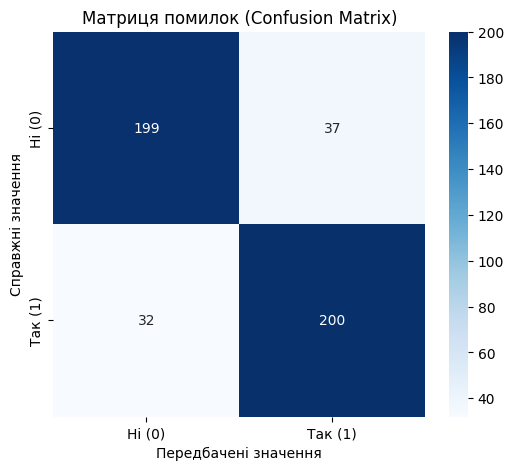

In [18]:
# Обчислення матриці помилок
conf = confusion_matrix(y_test, y_pred)

# Побудова теплової карти
plt.figure(figsize=(6, 5))
sns.heatmap(conf, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Ні (0)', 'Так (1)'],
            yticklabels=['Ні (0)', 'Так (1)'])
plt.title('Матриця помилок (Confusion Matrix)')
plt.xlabel('Передбачені значення')
plt.ylabel('Справжні значення')
plt.show()

In [26]:
# Створення DataFrame зі справжніми та передбаченими значеннями
df_compare = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

# Виведення 10 випадкових рядків
df_compare.sample(10, random_state=42)

,Actual,Predicted
55,0,0
63,0,0
33,1,1
297,0,0
72,0,0
228,1,1
209,1,1
9,0,0
428,0,0
231,1,1


**Висновок щодо якості логістичної регресії:**  
_Яких помилок більше? Чи достатньо однієї метрики Accuracy?_

У ході аналізу матриці помилок виявлено, що модель логістичної регресії припускається практично однакової кількості помилок першого та другого роду: хибнопозитивних прогнозів зафіксовано 37, а хибнонегативних — 32. Модель демонструє симетричну поведінку і не має викривлення в бік жодного з класів. За умов повного балансу класів метрики Accuracy цілком достатньо для узагальненої оцінки якості класифікації, однак матриця помилок додатково підтверджує, що модель однаково надійно виявляє як успішні випадки лікування, так і відсутність ефекту від зілля.

### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

In [27]:
# Завдання параметрів для пошуку
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs', 'liblinear'],
    'max_iter': [100, 200, 500]
}

param_dist = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs', 'liblinear'],
    'max_iter': [100, 200, 500]
}

In [28]:
# Підбір параметрів через GridSearchCV
grid_search = GridSearchCV(
    estimator=LogisticRegression(random_state=42),
    param_grid=param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)
grid_search.fit(X_train_scaled, y_train)

print("Найкращі параметри GridSearchCV:", grid_search.best_params_)
print(f"Найкраща точність на крос-валідації: {grid_search.best_score_:.4f}")

Найкращі параметри GridSearchCV: {'C': 10, 'max_iter': 100, 'solver': 'lbfgs'}
Найкраща точність на крос-валідації: 0.8749


In [29]:
# Підбір параметрів через RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=LogisticRegression(random_state=42),
    param_distributions=param_dist,
    n_iter=10,
    cv=3,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)
random_search.fit(X_train_scaled, y_train)

print("Найкращі параметри RandomizedSearchCV:", random_search.best_params_)
print(f"Найкраща точність на крос-валідації: {random_search.best_score_:.4f}")

Найкращі параметри RandomizedSearchCV: {'solver': 'liblinear', 'max_iter': 200, 'C': 100}
Найкраща точність на крос-валідації: 0.8749


In [30]:
# Отримання найкращої моделі та її оцінка
best_model = grid_search.best_estimator_
y_pred_tuned = best_model.predict(X_test_scaled)

print(f"Accuracy на тестовій вибірці: {accuracy_score(y_test, y_pred_tuned):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_tuned))

Accuracy на тестовій вибірці: 0.8504

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.84      0.85       236
           1       0.84      0.86      0.85       232

    accuracy                           0.85       468
   macro avg       0.85      0.85      0.85       468
weighted avg       0.85      0.85      0.85       468



**Висновок про підбір параметрів:**  
_Який метод пошуку обрав які параметри? Чи покращилась якість порівняно з базовою моделлю?_

Під час підбору методом GridSearchCV обрано параметри {'C': 10, 'max_iter': 100, 'solver': 'lbfgs'}, а методом RandomizedSearchCV — {'C': 100, 'max_iter': 200, 'solver': 'liblinear'}, при цьому обидва методи досягли однаково високої точності на крос-валідації (~87.49%). На тестовій вибірці налаштована модель показала точність 85.04%, що практично збігається з результатом базової моделі (85.26%). Це підтверджує, що базова логістична регресія вже працювала близько до свого теоретичного максимуму для даної лінійної структури даних.

### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

In [31]:
# Навчання Логістичної регресії, SVC та Дерева рішень
lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_test_scaled)

svc_model = SVC(random_state=42)
svc_model.fit(X_train_scaled, y_train)
y_pred_svc = svc_model.predict(X_test_scaled)

dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)  # Для дерева рішень масштабування не обов'язкове
y_pred_dt = dt_model.predict(X_test)

# Формування підсумкової таблиці метрик
comparison_df = pd.DataFrame({
    'Модель': ['Logistic Regression', 'SVC', 'Decision Tree'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_svc),
        accuracy_score(y_test, y_pred_dt)
    ],
    'F1-score': [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_svc),
        f1_score(y_test, y_pred_dt)
    ]
})

display(comparison_df)

# Автоматичне визначення найкращої моделі
best_row = comparison_df.loc[comparison_df['Accuracy'].idxmax()]
print(f"Найкраща модель: {best_row['Модель']} (Accuracy: {best_row['Accuracy']:.4f}, F1-score: {best_row['F1-score']:.4f})")

,Модель,Accuracy,F1-score
0,Logistic Regression,0.852564,0.852878
1,SVC,0.933761,0.932755
2,Decision Tree,0.826923,0.826552


Найкраща модель: SVC (Accuracy: 0.9338, F1-score: 0.9328)


### 13. Висновки до лабораторної роботи

Заповніть власними результатами (не залишайте відповіді з підказок):

1. Які особливості даних виявлено під час первинного аналізу?
2. Що показали дослідження викидів і кореляцій **на навчальній вибірці**?
3. Якої якості досягла базова логістична регресія?
4. Чи покращив підбір гіперпараметрів метрики моделі?
5. Яка з трьох моделей виявилася найкращою? Обґрунтуйте.

**Ваші висновки:**  
Під час первинного аналізу датасету з 2338 спостережень та 14 числових ознак не було виявлено пропущених значень і дублікатів, а цільова змінна Cured виявилася повністю збалансованою. Дослідження навчальної вибірки показало найбільшу кількість викидів в ознаках Witch's Brew, Chimera Fang та Unicorn Horn, а кореляційний аналіз виявив найсильніший зв'язок цільової змінної з ознаками Troll Hair та Witch's Brew за відсутності явної мультиколінеарності між незалежними змінними. Базова модель логістичної регресії досягла точності Accuracy = 0.8526 та F1-score = 0.8529. Підбір гіперпараметрів за допомогою GridSearchCV та RandomizedSearchCV практично не змінив метрики моделі на тестовій вибірці (Accuracy = 0.8504), оскільки лінійна регресія досягла свого межа для даних із такою структурою. Найкращою з трьох розглянутих моделей виявився метод опорних векторів (SVC) з точністю Accuracy = 0.9338 та F1-score = 0.9328, оскільки використання радіально-базисного ядра (RBF) дозволило ефективно врахувати складні нелінійні залежності між ознаками, які виявилися недоступними для логістичної регресії та одиночного дерева рішень.

---
**Перед здачею:** перевірте, що всі потрібні клітинки виконуються послідовно, а результати й висновки присутні у файлі `.ipynb`.